**by: [João Ataíde](https://www.joaoataide.com)**
# **CAP 08: Testes Não Paramétricos**

---



In [1]:
#importar bibliotecas
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import statistics as st
import scipy.stats as stats
from scipy.stats import norm, chi2, binomtest, rankdata

from statsmodels.stats.contingency_tables import mcnemar, cochrans_q

Os testes de hipóteses se dividem em paramétricos e não paramétricos. No capítulo 7 vimos que os `testes paramétricos` formulam hipóteses sobre parâmetros da população ($\mu$, $\sigma$, $\sigma^2$, $p$) e exigem suposições fortes, como normalidade e homogeneidade de variâncias.

Os `testes não paramétricos` formulam hipóteses sobre características qualitativas da população e podem ser aplicados a dados em escala nominal ou ordinal. Como fazem poucas suposições sobre a distribuição dos dados, também são chamados de `testes livres de distribuição`.

* Vantagens: não exigem normalidade, podem ser aplicados a dados qualitativos e envolvem cálculos mais simples.

* Desvantagens: ao transformar dados quantitativos em qualitativos (sinais ou postos) perdemos informação, e como são menos eficientes precisam de mais evidência (amostra maior ou diferenças maiores) para rejeitar $H_0$.

`OBS:` *Os testes paramétricos são mais poderosos, então devem ser preferidos sempre que seus pressupostos forem atendidos. Os não paramétricos são a alternativa quando os pressupostos são violados ou quando as variáveis são qualitativas.*

## **Classificação dos testes não paramétricos**

| Dimensão | Nível de mensuração | Teste |
|---|---|---|
| Uma amostra | Binária | Binomial |
| | Nominal ou ordinal | $\chi^2$ |
| | Ordinal | Teste dos sinais |
| Duas amostras emparelhadas | Binária | McNemar |
| | Ordinal | Teste dos sinais e Wilcoxon |
| Duas amostras independentes | Nominal ou ordinal | $\chi^2$ |
| | Ordinal | U de Mann-Whitney |
| $k$ amostras emparelhadas | Binária | Q de Cochran |
| | Ordinal | Friedman |
| $k$ amostras independentes | Nominal ou ordinal | $\chi^2$ |
| | Ordinal | Kruskal-Wallis |

Assim como no capítulo 7, vamos usar uma função para os passos 5 e 6 (decisão pelo p-valor).

In [2]:
def decisao(p_valor, alpha):
    if p_valor <= alpha:
        return f"P = {np.round(p_valor, 4)} <= {alpha}: rejeitamos H0"
    return f"P = {np.round(p_valor, 4)} > {alpha}: não rejeitamos H0"

E outra para desenhar a distribuição da estatística do teste com a região crítica (RC), a região de não rejeição (RN) e o valor calculado, como nas figuras do livro.

In [3]:
def regiao_critica(distribuicao, critico, estatistica, lado="bilateral", titulo="", eixo_x="Estatística"):

    # Intervalo do gráfico, incluindo o valor calculado
    inicio = min(distribuicao.ppf(0.0005), estatistica - 0.5)
    fim = max(distribuicao.ppf(0.9995), estatistica + 0.5)
    x = np.linspace(inicio, fim, 500)
    y = distribuicao.pdf(x)

    # Região crítica conforme o tipo de teste
    if lado == "bilateral":
        rc = (x <= -critico) | (x >= critico)
        marcas = [-critico, critico]
    elif lado == "esquerda":
        rc = x <= critico
        marcas = [critico]
    else:
        rc = x >= critico
        marcas = [critico]

    plt.plot(x, y, color='black')
    plt.fill_between(x, y, where=rc, color='red', alpha=0.5, label='RC')
    plt.fill_between(x, y, where=~rc, color='gray', alpha=0.2, label='RN')

    for m in marcas:
        plt.axvline(m, color='red', linestyle=':', linewidth=1)
        plt.text(m, 0.15 * y.max(), f' {np.round(m, 3)}', ha='left', color='red')

    plt.axvline(estatistica, color='darkorange', linestyle='--', label=f'Calculado = {np.round(estatistica, 3)}')
    plt.title(titulo)
    plt.xlabel(eixo_x)
    plt.ylabel('Densidade')
    plt.legend()

    # Exibir o gráfico
    plt.show()

## **Testes para Uma Amostra**

Uma amostra aleatória é extraída da população e testamos se os dados apresentam determinada característica ou distribuição.

### **Teste binomial**

Aplicado quando a variável é binária: sucesso ($X = 1$), com probabilidade $p$, ou fracasso ($X = 0$), com probabilidade $q = 1 - p$.

$H_0: p = p_0$

$H_1: p \neq p_0$

A probabilidade de obter $k$ sucessos em $N$ observações é:

$P[Y = k] = \binom{N}{k}\cdot p^k\cdot q^{N-k}$

No teste usamos a probabilidade de valores tão ou mais extremos que o observado, $P(Y \leq k) = \sum_{i=0}^{k}\binom{N}{i}\cdot p^i\cdot q^{N-i}$. Para um teste bilateral esse valor é dobrado.

`Grandes amostras` ($N > 25$): a distribuição de $Y$ se aproxima da normal, com correção de continuidade:

$Z_{cal} = \frac{|N\cdot\hat{p} - N\cdot p| - 0.5}{\sqrt{N\cdot p\cdot q}}$

#### Exemplo 1

Dezoito alunos de um curso intensivo de inglês escolheram entre dois métodos de ensino: 11 preferiram o método 1 e 7 o método 2. Há diferença na preferência ($\alpha = 5\%$)?

$H_0: p = q = 1/2$ e $H_1: p \neq q$

In [4]:
N = 18
k = 7  # Menor frequência observada (método 2)

# P(Y <= 7) somando as probabilidades da binomial
p_unilateral = sum(math.comb(N, i) * 0.5**i * 0.5**(N - i) for i in range(k + 1))

print(f"P(Y <= 7) = {np.round(p_unilateral, 3)}")
print(f"P bilateral = {np.round(2 * p_unilateral, 3)}")

P(Y <= 7) = 0.24
P bilateral = 0.481


In [5]:
# Conferindo com o scipy
resultado = binomtest(11, n=18, p=0.5, alternative='two-sided')
print(decisao(resultado.pvalue, 0.05))

P = 0.4807 > 0.05: não rejeitamos H0


Note que o p-valor bilateral é 0.481, maior que 5%, então não rejeitamos $H_0$: com 95% de confiança, não há diferença na preferência pelos dois métodos.

#### Exemplo 2

Mesmo caso com uma amostra maior: 30 alunos, sendo 18 no método 1 e 12 no método 2.

In [6]:
def teste_binomial_z(sucessos, N, p=0.5):

    p_chapeu = sucessos / N
    z_cal = (abs(N * p_chapeu - N * p) - 0.5) / np.sqrt(N * p * (1 - p))
    p_valor = 2 * (1 - norm.cdf(z_cal))  # Bilateral

    return z_cal, p_valor

z_cal, p_z = teste_binomial_z(18, 30)

print(f"Z calculado: {np.round(z_cal, 3)}")
print(decisao(p_z, 0.05))

Z calculado: 0.913
P = 0.3613 > 0.05: não rejeitamos H0


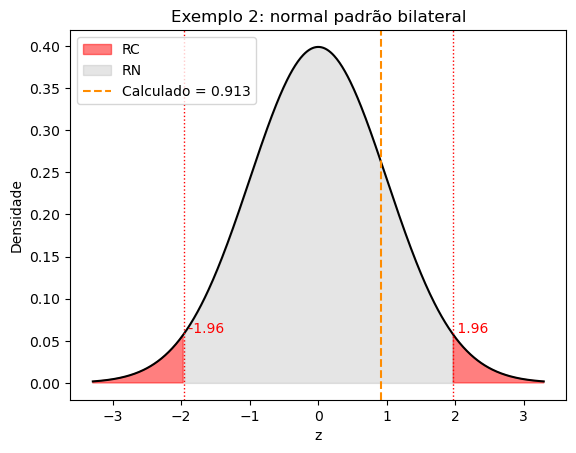

In [7]:
# Região crítica do Exemplo 2
regiao_critica(norm(), norm.ppf(0.975), z_cal, lado="bilateral",
               titulo='Exemplo 2: normal padrão bilateral', eixo_x='z')

Note que $Z_{cal} = 0.913$ está entre $-1.96$ e $1.96$, então não rejeitamos $H_0$: também com 30 alunos não há diferença na preferência pelos métodos.

`OBS:` *O livro traz P = 0.3524, mas pela tabela da normal a probabilidade unilateral de* $Z > 0.913$ *é 0.181, o que dá P = 0.361 no teste bilateral. A conclusão é a mesma.*

### **Teste qui-quadrado ($\chi^2$) para uma amostra**

Extensão do teste binomial para uma variável com duas ou mais categorias (nominal ou ordinal). Compara as frequências observadas com as esperadas.

$H_0:$ não há diferença significativa entre as frequências observadas e esperadas

$H_1:$ há diferença significativa entre as frequências observadas e esperadas

$\chi^2_{cal} = \sum_{i=1}^{k}\frac{(O_i - E_i)^2}{E_i} \sim \chi^2_{k-1}$

Rejeitamos $H_0$ se $\chi^2_{cal} > \chi^2_c$.

#### Exemplo 3

Uma loja de doces caseiros quer saber se a venda de brigadeiros varia com o dia da semana ($\alpha = 5\%$).

In [8]:
brigadeiros = pd.DataFrame({
    "Observadas": [35, 24, 27, 32, 25, 36, 31],
    "Esperadas": [30, 30, 30, 30, 30, 30, 30]
}, index=["Dom", "Seg", "Ter", "Qua", "Qui", "Sex", "Sáb"])

brigadeiros.T

,Dom,Seg,Ter,Qua,Qui,Sex,Sáb
Observadas,35,24,27,32,25,36,31
Esperadas,30,30,30,30,30,30,30


In [9]:
chi2_cal, p_chi2 = stats.chisquare(brigadeiros["Observadas"], brigadeiros["Esperadas"])

print(f"Qui-quadrado calculado: {np.round(chi2_cal, 3)}")
print(f"Qui-quadrado crítico (5%, 6 gl): {np.round(chi2.ppf(0.95, 6), 3)}")
print(decisao(p_chi2, 0.05))

Qui-quadrado calculado: 4.533
Qui-quadrado crítico (5%, 6 gl): 12.592
P = 0.6049 > 0.05: não rejeitamos H0


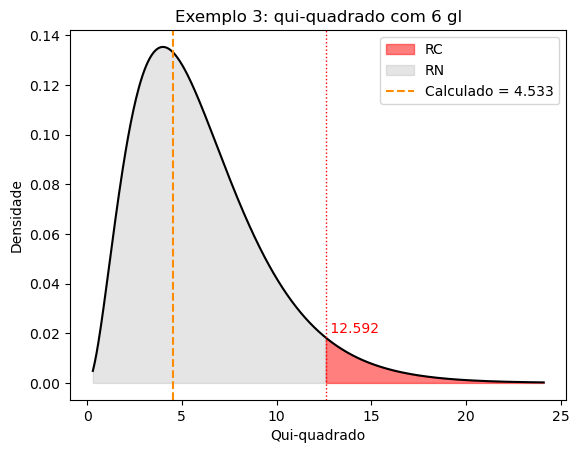

In [10]:
# Região crítica do Exemplo 3
regiao_critica(chi2(6), chi2.ppf(0.95, 6), chi2_cal, lado="direita",
               titulo='Exemplo 3: qui-quadrado com 6 gl', eixo_x='Qui-quadrado')

Note que $\chi^2_{cal} = 4.533$ é menor que $\chi^2_c = 12.592$, então não rejeitamos $H_0$: com 95% de confiança, a venda de brigadeiros não varia com o dia da semana.

### **Teste dos sinais para uma amostra**

Alternativa ao teste t para uma amostra quando os dados não são normais. A única exigência é que a variável seja contínua. O teste é baseado na mediana $\tilde{\mu}$:

$H_0: \tilde{\mu} = \tilde{\mu}_0$

$H_1: \tilde{\mu} \neq \tilde{\mu}_0$

Basicamente cada valor acima de $\tilde{\mu}_0$ vira um sinal (+) e cada valor abaixo vira (−), e os empates são excluídos. Sob $H_0$, os dois sinais são igualmente prováveis ($p = 1/2$).

* `Pequenas amostras` ($N \leq 25$): teste binomial com $p = 1/2$, sendo $k$ a menor frequência de sinais.
* `Grandes amostras` ($N > 25$): $Z = \frac{(X \pm 0.5) - N/2}{0.5\cdot\sqrt{N}}$, usando $X + 0.5$ se $X$ for a menor frequência e $X - 0.5$ se for a maior.

`OBS:` *Como só o sinal é usado, o teste perde bastante informação e tem baixo poder.*

#### Exemplo 4

Estima-se que a idade mediana de aposentadoria em uma cidade seja de 65 anos. Uma amostra de 20 aposentados foi coletada ($\alpha = 10\%$).

In [11]:
idade_aposentadoria = np.array([59, 62, 66, 37, 60, 64, 66, 70, 72, 61,
                                64, 66, 68, 72, 78, 93, 79, 65, 67, 59])
mediana_0 = 65

positivos = np.sum(idade_aposentadoria > mediana_0)
negativos = np.sum(idade_aposentadoria < mediana_0)
N = positivos + negativos  # Empates excluídos

print(f"Sinais (+): {positivos} | Sinais (-): {negativos} | N = {N}")

resultado = binomtest(min(positivos, negativos), n=N, p=0.5)
print(decisao(resultado.pvalue, 0.10))

Sinais (+): 11 | Sinais (-): 8 | N = 19
P = 0.6476 > 0.1: não rejeitamos H0


Note que há 11 sinais (+), 8 sinais (−) e um empate excluído ($N = 19$). O p-valor bilateral é 0.648, maior que 10%, então não rejeitamos $H_0$: com 90% de confiança, a idade mediana de aposentadoria é de 65 anos.

## **Testes para Duas Amostras Emparelhadas**

Verificam se duas amostras relacionadas diferem, como medidas antes e depois de um evento. Usamos o McNemar para variáveis binárias e os testes dos sinais e de Wilcoxon para variáveis ordinais.

### **Teste de McNemar**

Testa se há mudanças significativas antes e depois de um evento para uma variável binária, a partir de uma tabela de contingência 2 x 2:

| Antes \ Depois | + | − |
|---|---|---|
| **+** | A | B |
| **−** | C | D |

`B` e `C` contam quem mudou de resposta. Pela hipótese nula, as mudanças nas duas direções são igualmente prováveis:

$H_0: P(B) = P(C)$

$H_1: P(B) \neq P(C)$

$\chi^2_{cal} = \frac{(B - C)^2}{B + C}$, ou, com correção de continuidade, $\chi^2_{cal} = \frac{(|B - C| - 1)^2}{B + C}$, ambos com 1 grau de liberdade.

#### Exemplo 5

Sessenta trabalhadores indicaram se preferiam trabalhar em uma instituição particular ou pública, antes e depois de uma reforma da previdência dos servidores ($\alpha = 5\%$).

In [12]:
reforma = pd.DataFrame([[22, 3],
                        [21, 14]],
                       index=["Antes: Particular", "Antes: Pública"],
                       columns=["Depois: Particular", "Depois: Pública"])
reforma

,Depois: Particular,Depois: Pública
Antes: Particular,22,3
Antes: Pública,21,14


In [13]:
B = reforma.iloc[0, 1]  # Particular -> Pública
C = reforma.iloc[1, 0]  # Pública -> Particular

chi2_sem_correcao = (B - C)**2 / (B + C)
chi2_com_correcao = (abs(B - C) - 1)**2 / (B + C)

print(f"Qui-quadrado sem correção: {np.round(chi2_sem_correcao, 3)}")
print(f"Qui-quadrado com correção: {np.round(chi2_com_correcao, 3)}")
print(f"Qui-quadrado crítico (5%, 1 gl): {np.round(chi2.ppf(0.95, 1), 3)}")

Qui-quadrado sem correção: 13.5
Qui-quadrado com correção: 12.042
Qui-quadrado crítico (5%, 1 gl): 3.841


In [14]:
# Conferindo com o statsmodels
resultado = mcnemar(reforma.values, exact=False, correction=True)
print(decisao(resultado.pvalue, 0.05))

P = 0.0005 <= 0.05: rejeitamos H0


Note que $\chi^2_{cal} = 12.042$ (13.5 sem a correção) é maior que $\chi^2_c = 3.841$, então rejeitamos $H_0$: com 95% de confiança, a reforma mudou a preferência dos trabalhadores. Das 24 pessoas que mudaram de opinião, 21 passaram da instituição pública para a particular.

### **Teste dos sinais para duas amostras emparelhadas**

Alternativa ao teste t para amostras emparelhadas quando os dados não são normais. O sinal de cada par é dado pela diferença entre os valores, e os empates são excluídos. Pela hipótese nula a mediana das diferenças é zero, ou seja, o número de sinais (+) é igual ao de sinais (−):

$H_0: \tilde{\mu}_d = 0$

$H_1: \tilde{\mu}_d \neq 0$

O cálculo é o mesmo do teste dos sinais para uma amostra (binomial para $N \leq 25$ e normal para $N > 25$).

#### Exemplo 6

Produtividade (peças por hora) de 30 operários antes e depois de um treinamento ($\alpha = 5\%$).

In [15]:
produtividade = pd.DataFrame({
    "Antes": [36, 39, 27, 41, 40, 44, 38, 42, 40, 43, 37, 41, 38, 45, 40,
              39, 38, 39, 41, 36, 38, 40, 36, 40, 40, 38, 37, 40, 38, 40],
    "Depois": [40, 41, 29, 45, 39, 42, 39, 40, 42, 45, 35, 40, 38, 43, 40,
               42, 41, 39, 40, 38, 36, 38, 35, 42, 41, 40, 39, 42, 36, 40]
})

diferenca = produtividade["Depois"] - produtividade["Antes"]
positivos = np.sum(diferenca > 0)
negativos = np.sum(diferenca < 0)
N = positivos + negativos

print(f"Sinais (+): {positivos} | Sinais (-): {negativos} | Empates: {len(diferenca) - N} | N = {N}")

Sinais (+): 15 | Sinais (-): 11 | Empates: 4 | N = 26


In [16]:
def teste_sinais_z(positivos, negativos):

    N = positivos + negativos
    x = min(positivos, negativos)  # Menor frequência: usamos X + 0.5

    z_cal = ((x + 0.5) - N / 2) / (0.5 * np.sqrt(N))
    p_valor = 2 * norm.cdf(z_cal)  # Bilateral

    return z_cal, p_valor

z_cal, p_z = teste_sinais_z(positivos, negativos)

print(f"Z calculado: {np.round(z_cal, 3)}")
print(decisao(p_z, 0.05))

Z calculado: -0.588
P = 0.5563 > 0.05: não rejeitamos H0


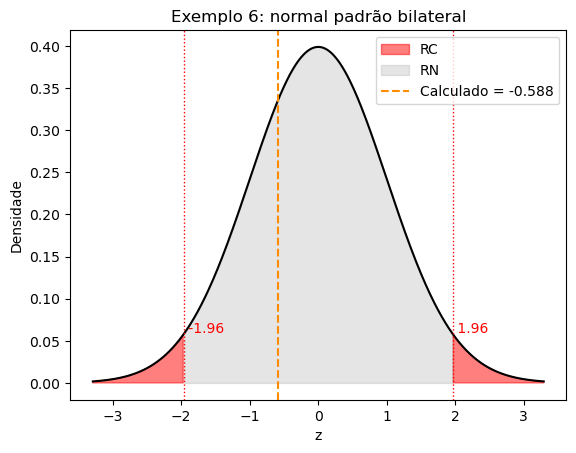

In [17]:
# Região crítica do Exemplo 6
regiao_critica(norm(), norm.ppf(0.975), z_cal, lado="bilateral",
               titulo='Exemplo 6: normal padrão bilateral', eixo_x='z')

Note que $Z_{cal} = -0.588$ está entre $-1.96$ e $1.96$ e o p-valor é 0.556, então não rejeitamos $H_0$: com 95% de confiança, o treinamento não mudou a produtividade.

`OBS:` *No passo 6 da solução com p-valor, o livro escreve "como P > 0,05, rejeitamos a hipótese nula", mas o correto é não rejeitar, como na solução pelo valor crítico.*

### **Teste de Wilcoxon**

Extensão mais poderosa do teste dos sinais: além da direção, considera a magnitude das diferenças entre os pares.

Procedimento:
1. Calcular a diferença $d_i$ de cada par e excluir os pares com $d_i = 0$.
2. Ordenar os $|d_i|$ e atribuir postos (diferenças iguais recebem a média dos postos).
3. Dar a cada posto o sinal de $d_i$ e somar os postos positivos ($S_p$) e negativos ($S_n$).

$H_0: \tilde{\mu}_d = 0$

$H_1: \tilde{\mu}_d \neq 0$

Para $N > 15$ usamos a aproximação normal, com correção para os empates:

$Z_{cal} = \frac{mín(S_p, S_n) - \frac{N\cdot(N+1)}{4}}{\sqrt{\frac{N\cdot(N+1)\cdot(2N+1)}{24} - \frac{\sum_{j=1}^{g}t_j^3 - \sum_{j=1}^{g}t_j}{48}}}$

sendo $g$ o número de grupos de postos empatados e $t_j$ o número de observações empatadas no grupo $j$.

#### Exemplo 7

Notas de 18 alunos em um exame de proficiência em inglês antes e depois de um curso intensivo de 6 meses ($\alpha = 5\%$).

In [18]:
notas = pd.DataFrame({
    "Antes": [56, 65, 70, 78, 47, 52, 64, 70, 72, 78, 80, 26, 55, 60, 71, 66, 60, 17],
    "Depois": [60, 62, 74, 79, 53, 59, 65, 75, 75, 88, 78, 26, 63, 59, 71, 75, 71, 24]
})

def wilcoxon(antes, depois):

    d = np.array(depois) - np.array(antes)
    d = d[d != 0]  # Excluir empates
    N = len(d)

    # Postos dos valores absolutos (média dos postos nos empates)
    postos = rankdata(np.abs(d))
    s_p = postos[d > 0].sum()
    s_n = postos[d < 0].sum()

    # Correção para empates
    _, t = np.unique(np.abs(d), return_counts=True)
    correcao = (np.sum(t**3) - np.sum(t)) / 48

    z_cal = (min(s_p, s_n) - N * (N + 1) / 4) / np.sqrt(N * (N + 1) * (2 * N + 1) / 24 - correcao)
    p_valor = 2 * norm.cdf(z_cal)  # Bilateral

    return s_p, s_n, z_cal, p_valor

s_p, s_n, z_cal, p_w = wilcoxon(notas["Antes"], notas["Depois"])

print(f"Sp = {s_p} | Sn = {s_n}")
print(f"Z calculado: {np.round(z_cal, 3)}")
print(decisao(p_w, 0.05))

Sp = 124.5 | Sn = 11.5
Z calculado: -2.925
P = 0.0034 <= 0.05: rejeitamos H0


In [19]:
# Conferindo com o scipy (aproximação normal, sem correção de continuidade)
stats.wilcoxon(notas["Antes"], notas["Depois"], zero_method='wilcox', correction=False, method='approx')

WilcoxonResult(statistic=np.float64(11.5), pvalue=np.float64(0.003444904942372219))

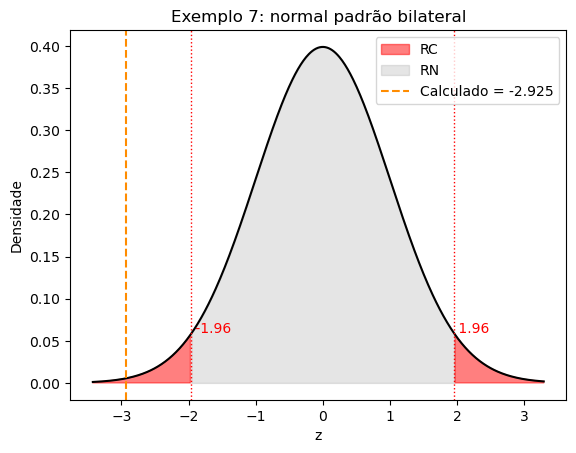

In [20]:
# Região crítica do Exemplo 7
regiao_critica(norm(), norm.ppf(0.975), z_cal, lado="bilateral",
               titulo='Exemplo 7: normal padrão bilateral', eixo_x='z')

Note que $S_p = 124.5$, $S_n = 11.5$ e $Z_{cal} = -2.925$, que está na região crítica ($Z_{cal} < -1.96$). Como o p-valor é 0.0034, rejeitamos $H_0$: com 95% de confiança, o curso mudou o desempenho dos alunos, e como quase todas as diferenças são positivas, as notas melhoraram.

## **Testes para Duas Amostras Independentes**

Comparam duas populações a partir de amostras independentes, que não precisam ter o mesmo tamanho.

### **Teste qui-quadrado ($\chi^2$) para duas amostras independentes**

O mesmo teste do capítulo 3: compara as frequências observadas em cada célula da tabela de contingência com as frequências esperadas sob a hipótese de não associação.

$\chi^2_{cal} = \sum_{i=1}^{I}\sum_{j=1}^{J}\frac{(O_{ij} - E_{ij})^2}{E_{ij}} \sim \chi^2_{(I-1)\cdot(J-1)}$

#### Exemplo 8

Satisfação de 200 clientes de três operadoras de plano de saúde, o mesmo exemplo do capítulo 3 ($\alpha = 5\%$).

In [21]:
plano_saude = pd.DataFrame([[40, 16, 12],
                            [32, 24, 16],
                            [24, 32, 4]],
                           index=["Total Health", "Viva Vida", "Mena Saúde"],
                           columns=["Baixo", "Médio", "Alto"])

chi2_cal, p_chi2, gl, esperados = stats.chi2_contingency(plano_saude)

print(f"Qui-quadrado calculado: {np.round(chi2_cal, 3)} ({gl} gl)")
print(f"Qui-quadrado crítico (5%): {np.round(chi2.ppf(0.95, gl), 3)}")
print(decisao(p_chi2, 0.05))

pd.DataFrame(esperados, index=plano_saude.index, columns=plano_saude.columns).round(1)

Qui-quadrado calculado: 15.861 (4 gl)
Qui-quadrado crítico (5%): 9.488
P = 0.0032 <= 0.05: rejeitamos H0


,Baixo,Médio,Alto
Total Health,32.6,24.5,10.9
Viva Vida,34.6,25.9,11.5
Mena Saúde,28.8,21.6,9.6


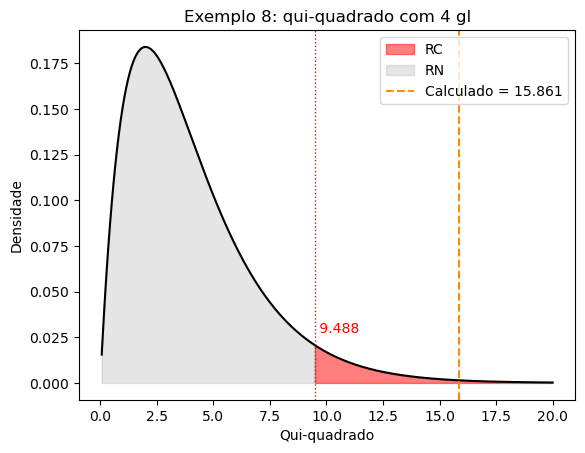

In [22]:
# Região crítica do Exemplo 8
regiao_critica(chi2(4), chi2.ppf(0.95, 4), chi2_cal, lado="direita",
               titulo='Exemplo 8: qui-quadrado com 4 gl', eixo_x='Qui-quadrado')

Note que $\chi^2_{cal} = 15.861$ é maior que $\chi^2_c = 9.488$, então rejeitamos $H_0$: com 95% de confiança, existe associação entre a operadora e o nível de satisfação. A tabela acima mostra as frequências esperadas caso não houvesse associação.

### **Teste U de Mann-Whitney**

Um dos testes não paramétricos mais poderosos, é a versão não paramétrica do teste t para duas amostras independentes. Testa a igualdade das medianas:

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2$

$H_1: \tilde{\mu}_1 \neq \tilde{\mu}_2$

Procedimento:
1. Juntar as duas amostras ($N = N_1 + N_2$), sendo $N_1$ a menor, e atribuir postos de 1 a $N$ (empates recebem a média dos postos).
2. Somar os postos de cada amostra ($R_1$ e $R_2$).
3. Calcular $U_1 = N_1\cdot N_2 + \frac{N_1\cdot(N_1+1)}{2} - R_1$ e $U_2 = N_1\cdot N_2 + \frac{N_2\cdot(N_2+1)}{2} - R_2$.
4. A estatística é $U_{cal} = mín(U_1, U_2)$, e rejeitamos $H_0$ se $U_{cal} < U_c$ (Tabela J do livro).

`Grandes amostras` ($N_2 > 20$):

$Z_{cal} = \frac{U - \frac{N_1\cdot N_2}{2}}{\sqrt{\frac{N_1\cdot N_2}{N\cdot(N-1)}\cdot\left(\frac{N^3 - N}{12} - \frac{\sum_{j=1}^{g}t_j^3 - \sum_{j=1}^{g}t_j}{12}\right)}}$

#### Exemplo 9

Diâmetro (mm) das peças produzidas por duas máquinas. As duas amostras vêm de populações com medianas iguais ($\alpha = 5\%$)?

In [23]:
maquina_a = [48.50, 48.65, 48.58, 48.55, 48.66, 48.64, 48.50, 48.72]
maquina_b = [48.75, 48.64, 48.80, 48.85, 48.78, 48.79, 49.20]

# Normalidade das amostras
for nome, maquina in [("Máquina A", maquina_a), ("Máquina B", maquina_b)]:
    _, p_normal = stats.shapiro(maquina)
    print(f"Shapiro-Wilk {nome}: {decisao(p_normal, 0.05)}")

Shapiro-Wilk Máquina A: P = 0.5202 > 0.05: não rejeitamos H0
Shapiro-Wilk Máquina B: P = 0.0325 <= 0.05: rejeitamos H0


In [24]:
def mann_whitney(amostra_1, amostra_2):

    # amostra_1 deve ser a menor
    n1, n2 = len(amostra_1), len(amostra_2)
    N = n1 + n2

    postos = rankdata(np.concatenate([amostra_1, amostra_2]))
    r1 = postos[:n1].sum()
    r2 = postos[n1:].sum()

    u1 = n1 * n2 + n1 * (n1 + 1) / 2 - r1
    u2 = n1 * n2 + n2 * (n2 + 1) / 2 - r2
    u_cal = min(u1, u2)

    # Aproximação normal com correção para empates
    _, t = np.unique(postos, return_counts=True)
    variancia = (n1 * n2 / (N * (N - 1))) * ((N**3 - N) / 12 - (np.sum(t**3) - np.sum(t)) / 12)
    z_cal = (u_cal - n1 * n2 / 2) / np.sqrt(variancia)

    return r1, r2, u_cal, z_cal

r1, r2, u_cal, z_cal = mann_whitney(maquina_b, maquina_a)

print(f"R1 (máquina B) = {r1} | R2 (máquina A) = {r2}")
print(f"U calculado: {u_cal}")

R1 (máquina B) = 80.5 | R2 (máquina A) = 39.5
U calculado: 3.5


Note que a máquina B não segue distribuição normal, por isso usamos o Mann-Whitney. Como $U_{cal} = 3.5$ é menor que $U_c = 10$ ($N_1 = 7$, $N_2 = 8$, teste bilateral com $\alpha = 5\%$, Tabela J do livro), rejeitamos $H_0$: com 95% de confiança, os diâmetros medianos das peças das duas máquinas são diferentes.

#### Exemplo 10

Mesmo com a amostra pequena, qual seria o resultado pela aproximação normal?

In [25]:
print(f"Z calculado: {np.round(z_cal, 3)}")
print(decisao(2 * norm.cdf(z_cal), 0.05))

Z calculado: -2.84
P = 0.0045 <= 0.05: rejeitamos H0


In [26]:
# Conferindo com o scipy
stats.mannwhitneyu(maquina_b, maquina_a, use_continuity=False, method='asymptotic')

MannwhitneyuResult(statistic=np.float64(52.5), pvalue=np.float64(0.004505689306881697))

Note que $Z_{cal} = -2.840$ é menor que $-1.96$ e o p-valor é 0.0045, então a aproximação normal leva à mesma conclusão: as medianas das duas máquinas são diferentes.

`OBS:` *O scipy mostra* $U = 52.5$*, que é o* $U_1$ *da primeira amostra passada para a função. Como* $U_1 + U_2 = N_1\cdot N_2$*, o p-valor é o mesmo.*

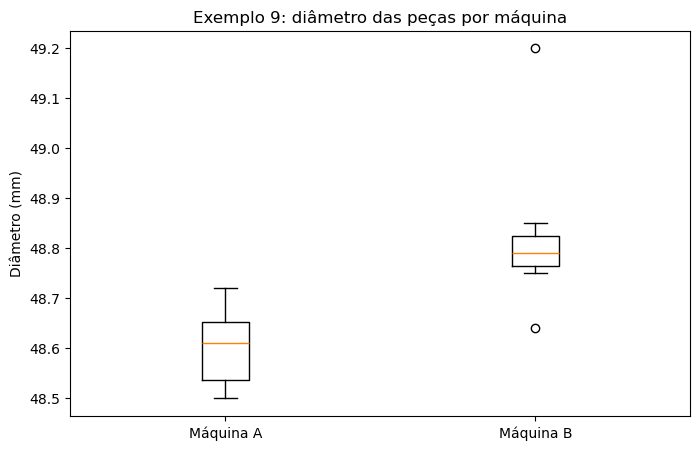

In [27]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.boxplot([maquina_a, maquina_b])
ax.set_xticks([1, 2], ["Máquina A", "Máquina B"])
ax.set_ylabel('Diâmetro (mm)')
ax.set_title('Exemplo 9: diâmetro das peças por máquina')

# Exibir o gráfico
plt.show()

## **Testes para k Amostras Emparelhadas**

Analisam se $k \geq 3$ amostras emparelhadas foram extraídas da mesma população. Usamos o Q de Cochran para variáveis binárias e o teste de Friedman para variáveis ordinais.

### **Teste Q de Cochran**

Extensão do McNemar para $k$ grupos relacionados com dados binários. Os dados ficam em uma tabela com $N$ linhas (casos) e $k$ colunas (grupos ou condições).

$H_0: p_1 = p_2 = \cdots = p_k$

$H_1: \exists_{(i,j)}\ p_i \neq p_j,\ i \neq j$

$Q_{cal} = \frac{k\cdot(k-1)\cdot\sum_{j=1}^{k}(G_j - \overline{G})^2}{k\cdot\sum_{i=1}^{N}L_i - \sum_{i=1}^{N}L_i^2} \sim \chi^2_{k-1}$

sendo $G_j$ o total de sucessos na coluna $j$, $\overline{G}$ a média dos $G_j$ e $L_i$ o total de sucessos na linha $i$.

#### Exemplo 11

Vinte consumidores avaliaram três supermercados como satisfatório (1) ou não (0). A proporção de boas avaliações é a mesma nos três ($\alpha = 10\%$)?

In [28]:
supermercados = pd.DataFrame({
    "A": [1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0],
    "B": [1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0],
    "C": [1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
})

def q_cochran(dados):

    k = dados.shape[1]
    G = dados.sum(axis=0)  # Sucessos por coluna
    L = dados.sum(axis=1)  # Sucessos por linha

    q_cal = k * (k - 1) * np.sum((G - G.mean())**2) / (k * L.sum() - np.sum(L**2))
    p_valor = 1 - chi2.cdf(q_cal, k - 1)

    return q_cal, p_valor

q_cal, p_q = q_cochran(supermercados)

print(f"Sucessos por supermercado: {supermercados.sum().to_dict()}")
print(f"Q calculado: {np.round(q_cal, 3)}")
print(f"Qui-quadrado crítico (10%, 2 gl): {np.round(chi2.ppf(0.90, 2), 3)}")
print(decisao(p_q, 0.10))

Sucessos por supermercado: {'A': 11, 'B': 11, 'C': 16}
Q calculado: 4.167
Qui-quadrado crítico (10%, 2 gl): 4.605
P = 0.1245 > 0.1: não rejeitamos H0


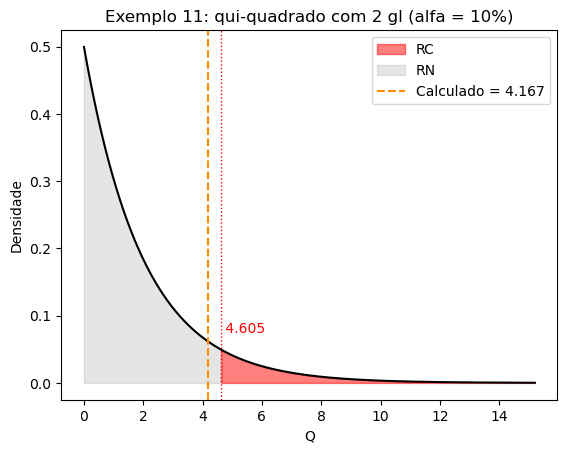

In [29]:
# Região crítica do Exemplo 11
regiao_critica(chi2(2), chi2.ppf(0.90, 2), q_cal, lado="direita",
               titulo='Exemplo 11: qui-quadrado com 2 gl (alfa = 10%)', eixo_x='Q')

In [30]:
# Conferindo com o statsmodels
resultado = cochrans_q(supermercados.values)
print(f"Q = {np.round(resultado.statistic, 3)} | P = {np.round(resultado.pvalue, 4)}")

Q = 4.167 | P = 0.1245


Note que $Q_{cal} = 4.167$ é menor que $\chi^2_c = 4.605$, então não rejeitamos $H_0$: com 90% de confiança, a proporção de clientes satisfeitos é a mesma nos três supermercados.

### **Teste de Friedman**

Extensão do teste de Wilcoxon para $k \geq 3$ amostras emparelhadas, e alternativa à ANOVA quando a normalidade e a homogeneidade de variâncias são violadas.

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2 = \cdots = \tilde{\mu}_k$

$H_1: \exists_{(i,j)}\ \tilde{\mu}_i \neq \tilde{\mu}_j,\ i \neq j$

Atribuímos postos de 1 a $k$ dentro de cada linha e somamos os postos de cada coluna ($R_j$):

$F_{r,cal} = \frac{12}{N\cdot k\cdot(k+1)}\cdot\sum_{j=1}^{k}R_j^2 - 3\cdot N\cdot(k+1)$

Com empates dentro das linhas, a estatística é corrigida:

$F'_{r,cal} = \frac{12\cdot\sum_{j=1}^{k}R_j^2 - 3\cdot N^2\cdot k\cdot(k+1)^2}{N\cdot k\cdot(k+1) + \frac{N\cdot k - \sum_{i=1}^{N}\sum_{j=1}^{g_i}t_{ij}^3}{k-1}}$

Para $N$ e $k$ grandes, $F_r \sim \chi^2_{k-1}$.

#### Exemplo 12

Peso de 15 pacientes antes do tratamento (AT), pós-tratamento (PT) e três meses depois (D3M). O tratamento oferece resultado ($\alpha = 5\%$)?

In [31]:
pesos = pd.DataFrame({
    "AT": [65, 89, 96, 90, 70, 72, 87, 74, 66, 135, 82, 76, 94, 80, 73],
    "PT": [62, 85, 95, 84, 70, 65, 84, 74, 64, 132, 75, 73, 90, 80, 70],
    "D3M": [58, 80, 95, 79, 66, 62, 77, 69, 62, 132, 71, 67, 88, 77, 68]
})

# Postos dentro de cada linha
postos = pesos.rank(axis=1)
print(f"Soma dos postos: {postos.sum().to_dict()}")
print(f"Média dos postos: {postos.mean().round(3).to_dict()}")

Soma dos postos: {'AT': 43.5, 'PT': 30.5, 'D3M': 16.0}
Média dos postos: {'AT': 2.9, 'PT': 2.033, 'D3M': 1.067}


In [32]:
def friedman(dados):

    N, k = dados.shape
    postos = dados.rank(axis=1)
    R = postos.sum(axis=0)

    # Sem correção
    f_r = 12 / (N * k * (k + 1)) * np.sum(R**2) - 3 * N * (k + 1)

    # Com correção para empates dentro das linhas
    soma_t3 = sum(np.sum(np.unique(linha, return_counts=True)[1]**3) for linha in dados.values)
    f_r_corrigido = (12 * np.sum(R**2) - 3 * N**2 * k * (k + 1)**2) / (N * k * (k + 1) + (N * k - soma_t3) / (k - 1))

    return f_r, f_r_corrigido

f_r, f_r_corrigido = friedman(pesos)

print(f"Friedman sem correção: {np.round(f_r, 3)}")
print(f"Friedman com correção: {np.round(f_r_corrigido, 3)}")
print(f"Qui-quadrado crítico (5%, 2 gl): {np.round(chi2.ppf(0.95, 2), 3)}")

Friedman sem correção: 25.233
Friedman com correção: 27.527
Qui-quadrado crítico (5%, 2 gl): 5.991


In [33]:
# Conferindo com o scipy (já aplica a correção para empates)
stats.friedmanchisquare(pesos["AT"], pesos["PT"], pesos["D3M"])

FriedmanchisquareResult(statistic=np.float64(27.527272727272713), pvalue=np.float64(1.0532432302056965e-06))

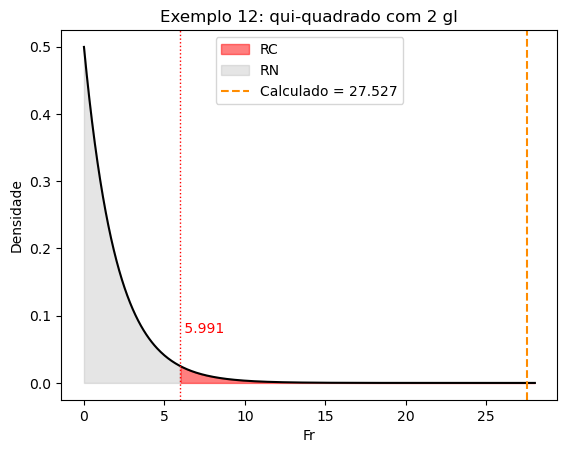

In [34]:
# Região crítica do Exemplo 12
regiao_critica(chi2(2), chi2.ppf(0.95, 2), f_r_corrigido, lado="direita",
               titulo='Exemplo 12: qui-quadrado com 2 gl', eixo_x='Fr')

Note que $F'_{r,cal} = 27.527$ (25.233 sem a correção) é muito maior que $\chi^2_c = 5.991$, então rejeitamos $H_0$: com 95% de confiança, o tratamento oferece resultado. A média dos postos cai de 2.9 (antes) para 1.07 (três meses depois), ou seja, o peso diminuiu.

## **Testes para k Amostras Independentes**

Avaliam se $k \geq 3$ amostras independentes vêm da mesma população. Usamos o $\chi^2$ para variáveis nominais ou ordinais e o Kruskal-Wallis para variáveis ordinais.

### **Teste qui-quadrado ($\chi^2$) para k amostras independentes**

Extensão direta do teste para duas amostras. As linhas da tabela de contingência são as categorias da variável e as colunas são os grupos.

$H_0:$ não há diferença significativa entre os $k$ grupos

$H_1:$ há diferença significativa entre os $k$ grupos

#### Exemplo 13

Produtividade (baixa, média, alta) dos funcionários de uma empresa em cada um dos quatro turnos de trabalho ($\alpha = 5\%$).

In [35]:
turnos = pd.DataFrame([[50, 60, 40, 50],
                       [80, 90, 80, 80],
                       [270, 200, 180, 170]],
                      index=["Baixa", "Média", "Alta"],
                      columns=["Turno 1", "Turno 2", "Turno 3", "Turno 4"])

chi2_cal, p_chi2, gl, esperados = stats.chi2_contingency(turnos)

print(f"Qui-quadrado calculado: {np.round(chi2_cal, 3)} ({gl} gl)")
print(f"Qui-quadrado crítico (5%): {np.round(chi2.ppf(0.95, gl), 3)}")
print(decisao(p_chi2, 0.05))

Qui-quadrado calculado: 13.143 (6 gl)
Qui-quadrado crítico (5%): 12.592
P = 0.0408 <= 0.05: rejeitamos H0


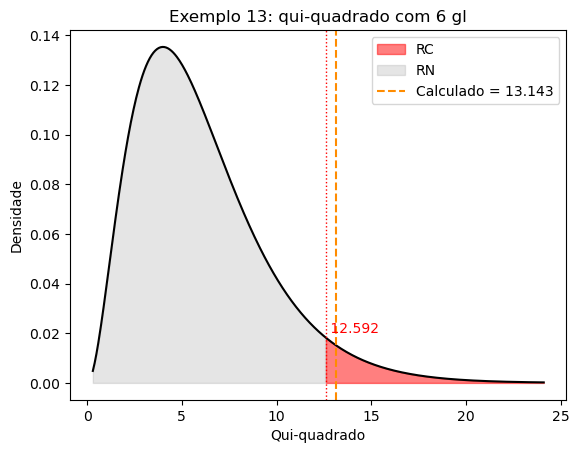

In [36]:
# Região crítica do Exemplo 13
regiao_critica(chi2(6), chi2.ppf(0.95, 6), chi2_cal, lado="direita",
               titulo='Exemplo 13: qui-quadrado com 6 gl', eixo_x='Qui-quadrado')

Note que $\chi^2_{cal} = 13.143$ é maior que $\chi^2_c = 12.592$ e o p-valor é 0.041, então rejeitamos $H_0$: com 95% de confiança, a produtividade varia com o turno. O turno 1, por exemplo, tem mais funcionários de alta produtividade do que o esperado (270 contra 243).

### **Teste de Kruskal-Wallis**

Verifica se $k > 2$ amostras independentes vêm da mesma população. É a alternativa à ANOVA quando a normalidade e a homogeneidade de variâncias são violadas, quando a amostra é pequena ou quando a variável é ordinal. Para $k = 2$ equivale ao Mann-Whitney.

$H_0: \tilde{\mu}_1 = \tilde{\mu}_2 = \cdots = \tilde{\mu}_k$

$H_1: \exists_{(i,j)}\ \tilde{\mu}_i \neq \tilde{\mu}_j,\ i \neq j$

Todas as $N$ observações recebem postos de 1 a $N$, e somamos os postos de cada grupo ($R_j$):

$H_{cal} = \frac{12}{N\cdot(N+1)}\cdot\sum_{j=1}^{k}\frac{R_j^2}{n_j} - 3\cdot(N+1)$

Com empates: $H'_{cal} = \frac{H_{cal}}{1 - \frac{\sum_{j=1}^{g}(t_j^3 - t_j)}{N^3 - N}}$

Se $k = 3$ e todos os $n_j \leq 5$ usamos a Tabela L do livro; caso contrário, $H \sim \chi^2_{k-1}$.

#### Exemplo 14

Nível de estresse de 36 pacientes após três tratamentos diferentes, 12 em cada um ($\alpha = 1\%$).

In [37]:
estresse = pd.DataFrame({
    "A": [6, 5, 4, 5, 3, 4, 5, 2, 4, 3, 5, 2],
    "B": [6, 7, 5, 8, 7, 8, 6, 9, 8, 6, 8, 8],
    "C": [5, 9, 8, 7, 9, 11, 7, 8, 9, 10, 7, 8]
})

def kruskal_wallis(*grupos):

    n = np.array([len(g) for g in grupos])
    N = n.sum()
    postos = rankdata(np.concatenate(grupos))

    # Soma dos postos de cada grupo
    limites = np.cumsum(n)[:-1]
    R = np.array([p.sum() for p in np.split(postos, limites)])

    h_cal = 12 / (N * (N + 1)) * np.sum(R**2 / n) - 3 * (N + 1)

    # Correção para empates
    _, t = np.unique(postos, return_counts=True)
    h_corrigido = h_cal / (1 - np.sum(t**3 - t) / (N**3 - N))

    return R, h_cal, h_corrigido

R, h_cal, h_corrigido = kruskal_wallis(estresse["A"], estresse["B"], estresse["C"])

print(f"Soma dos postos: {R}")
print(f"H calculado: {np.round(h_cal, 3)}")
print(f"H corrigido: {np.round(h_corrigido, 3)}")
print(f"Qui-quadrado crítico (1%, 2 gl): {np.round(chi2.ppf(0.99, 2), 3)}")

Soma dos postos: [ 85.5 262.  318.5]
H calculado: 22.181
H corrigido: 22.662
Qui-quadrado crítico (1%, 2 gl): 9.21


In [38]:
# Conferindo com o scipy (já aplica a correção para empates)
stats.kruskal(estresse["A"], estresse["B"], estresse["C"])

KruskalResult(statistic=np.float64(22.66179048871358), pvalue=np.float64(1.1996504475044963e-05))

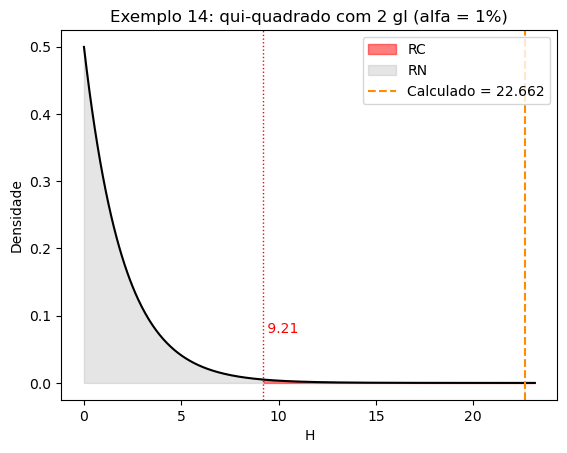

In [39]:
# Região crítica do Exemplo 14
regiao_critica(chi2(2), chi2.ppf(0.99, 2), h_corrigido, lado="direita",
               titulo='Exemplo 14: qui-quadrado com 2 gl (alfa = 1%)', eixo_x='H')

Note que $H'_{cal} = 22.662$ (22.181 sem a correção) é maior que $\chi^2_c = 9.210$, então rejeitamos $H_0$: com 99% de confiança, os tratamentos levam a níveis de estresse diferentes. O tratamento A tem a menor soma de postos (85.5), ou seja, os menores níveis de estresse.

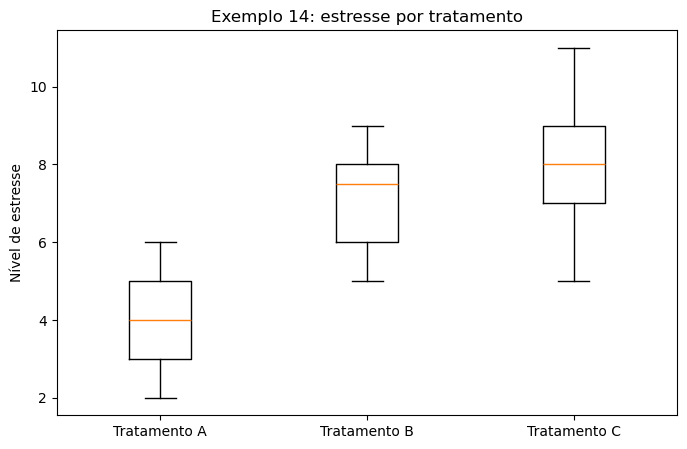

In [40]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.boxplot([estresse["A"], estresse["B"], estresse["C"]])
ax.set_xticks([1, 2, 3], ["Tratamento A", "Tratamento B", "Tratamento C"])
ax.set_ylabel('Nível de estresse')
ax.set_title('Exemplo 14: estresse por tratamento')

# Exibir o gráfico
plt.show()

## **Exercícios Testes Não Paramétricos**

### Exercício 5

Vinte consumidores provaram dois tipos de café: 8 escolheram a marca A e 12 a marca B. Há diferença na preferência ($\alpha = 5\%$)?

In [41]:
#Variável binária e N <= 25: teste binomial
resultado = binomtest(8, n=20, p=0.5)
print(decisao(resultado.pvalue, 0.05))

P = 0.5034 > 0.05: não rejeitamos H0


Note que o p-valor bilateral é 0.503, maior que 5%, então não rejeitamos $H_0$: não há diferença na preferência dos consumidores pelas duas marcas de café.

### Exercício 6

Sessenta leitores escolheram um entre três livros de romance: 29 o livro A, 15 o B e 16 o C. Há diferença na preferência ($\alpha = 5\%$)?

In [42]:
#Uma variável com 3 categorias: qui-quadrado para uma amostra (esperado = 20 em cada)
chi2_6, p_6 = stats.chisquare([29, 15, 16])

print(f"Qui-quadrado calculado: {np.round(chi2_6, 3)}")
print(f"Qui-quadrado crítico (5%, 2 gl): {np.round(chi2.ppf(0.95, 2), 3)}")
print(decisao(p_6, 0.05))

Qui-quadrado calculado: 6.1
Qui-quadrado crítico (5%, 2 gl): 5.991
P = 0.0474 <= 0.05: rejeitamos H0


Note que $\chi^2_{cal} = 6.1$ é maior que $\chi^2_c = 5.991$ (P = 0.047), então rejeitamos $H_0$: com 95% de confiança, há diferença na preferência dos leitores, puxada pelo livro A (29 escolhas contra 20 esperadas).

### Exercício 7

Peso de 20 adolescentes antes e depois de 30 dias de dieta. Houve redução ($\alpha = 5\%$)?

$H_0: \tilde{\mu}_d = 0$ e $H_1: \tilde{\mu}_d > 0$, com $d = antes - depois$ (unilateral à direita)

In [43]:
dieta = pd.DataFrame({
    "Antes": [58, 67, 72, 88, 77, 67, 75, 69, 104, 66, 58, 59, 61, 67, 73, 58, 67, 67, 78, 85],
    "Depois": [56, 62, 65, 84, 72, 68, 76, 62, 97, 65, 59, 60, 62, 63, 65, 58, 62, 64, 72, 80]
})

# Normalidade das diferenças
_, p_normal_7 = stats.shapiro(dieta["Antes"] - dieta["Depois"])
print(f"Shapiro-Wilk das diferenças: {decisao(p_normal_7, 0.05)}")

#Wilcoxon unilateral
resultado = stats.wilcoxon(dieta["Antes"], dieta["Depois"], zero_method='wilcox',
                           correction=False, alternative='greater', method='approx')
print(f"Wilcoxon: {decisao(resultado.pvalue, 0.05)}")

Shapiro-Wilk das diferenças: P = 0.0248 <= 0.05: rejeitamos H0
Wilcoxon: P = 0.0009 <= 0.05: rejeitamos H0


Note que as diferenças não seguem distribuição normal (P = 0.025), então usamos o Wilcoxon no lugar do teste t. Como o p-valor unilateral é 0.0009, rejeitamos $H_0$: com 95% de confiança, houve redução de peso depois da dieta.

### Exercício 8

Tempo de atendimento de 22 clientes em cada uma de duas agências bancárias. As medianas são iguais ($\alpha = 5\%$)?

In [44]:
agencia_a = [6.24, 8.47, 6.54, 6.87, 2.24, 5.36, 7.09, 7.56, 6.88, 8.04, 7.05,
             6.58, 8.14, 8.30, 2.69, 6.14, 7.14, 7.22, 7.58, 6.11, 7.25, 7.50]
agencia_b = [8.14, 6.54, 6.66, 7.85, 8.03, 5.68, 3.05, 5.78, 6.43, 6.39, 7.64,
             6.97, 8.07, 8.33, 7.14, 6.58, 5.98, 6.22, 7.08, 7.62, 5.69, 8.04]

#N2 > 20: Mann-Whitney com aproximação normal
r1_8, r2_8, u_8, z_8 = mann_whitney(agencia_a, agencia_b)

print(f"U calculado: {u_8}")
print(f"Z calculado: {np.round(z_8, 3)}")
print(decisao(2 * norm.cdf(z_8), 0.05))

U calculado: 236.5
Z calculado: -0.129
P = 0.8973 > 0.05: não rejeitamos H0


Note que $Z_{cal} = -0.129$ está entre $-1.96$ e $1.96$ (P = 0.897), então não rejeitamos $H_0$: as duas amostras vêm de populações com o mesmo tempo mediano de atendimento.

### Exercício 9

Vinte alunos de Administração avaliaram o aprendizado em três disciplinas como alto (1) ou baixo (0). A proporção de alunos com alto aprendizado é a mesma nas três ($\alpha = 2.5\%$)?

In [45]:
disciplinas = pd.DataFrame({
    "A": [0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1],
    "B": [1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1],
    "C": [1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
})

#Dados binários, 3 amostras emparelhadas: Q de Cochran
q_9, p_9 = q_cochran(disciplinas)

print(f"Alto aprendizado por disciplina: {disciplinas.sum().to_dict()}")
print(f"Q calculado: {np.round(q_9, 3)}")
print(f"Qui-quadrado crítico (2.5%, 2 gl): {np.round(chi2.ppf(0.975, 2), 3)}")
print(decisao(p_9, 0.025))

Alto aprendizado por disciplina: {'A': 8, 'B': 12, 'C': 16}
Q calculado: 8.727
Qui-quadrado crítico (2.5%, 2 gl): 7.378
P = 0.0127 <= 0.025: rejeitamos H0


Note que $Q_{cal} = 8.727$ é maior que $\chi^2_c = 7.378$ (P = 0.013 < 0.025), então rejeitamos $H_0$: com 97.5% de confiança, a proporção de alunos com alto aprendizado não é a mesma nas três disciplinas (8, 12 e 16 alunos em A, B e C).

### Exercício 10

Quinze consumidores avaliaram a satisfação (1 = baixa, 2 = média, 3 = alta) com três serviços bancários. Há diferença entre os serviços ($\alpha = 5\%$)?

In [46]:
servicos = pd.DataFrame({
    "A": [3, 2, 1, 3, 1, 3, 3, 2, 3, 2, 1, 3, 3, 2, 3],
    "B": [2, 2, 2, 2, 1, 2, 3, 2, 2, 1, 1, 1, 2, 1, 1],
    "C": [3, 2, 1, 2, 1, 1, 2, 1, 2, 1, 2, 1, 1, 2, 2]
})

#Variável ordinal, 3 amostras emparelhadas: Friedman
f_10, f_10_corrigido = friedman(servicos)

print(f"Friedman com correção: {np.round(f_10_corrigido, 3)}")
print(f"Qui-quadrado crítico (5%, 2 gl): {np.round(chi2.ppf(0.95, 2), 3)}")
print(decisao(1 - chi2.cdf(f_10_corrigido, 2), 0.05))

Friedman com correção: 9.19
Qui-quadrado crítico (5%, 2 gl): 5.991
P = 0.0101 <= 0.05: rejeitamos H0


Note que $F'_{r,cal} = 9.19$ é maior que $\chi^2_c = 5.991$ (P = 0.010), então rejeitamos $H_0$: com 95% de confiança, há diferença na satisfação com os três serviços. O serviço A é o mais bem avaliado, com a maior soma de postos (38, contra 26.5 do B e 25.5 do C).